# LAB | In God we trust, everyone else bring the data

**Scenario:** you are a marketing analyst. The CMO wants to split a **$500K monthly budget across the marketing channels** and asks you for a **statistically rigorous** recommendation. A false positive means moving money to a channel that isn't really better.

**How to use this notebook:**
- Cells marked **`# TODO`** are yours to complete. Replace every `...` with your code.
- 💡 **Hints** point to the statistics notebook (`03_statistical_analysis.ipynb`), where you saw each idea.
- Run the cells **in order**, top to bottom.

| Part | You will… | Concept from class |
|---|---|---|
| 1 | Find, load and clean a real dataset; compute metrics | A score is an **estimate** |
| 2 | Compare channels (t-test, Fisher) + effect size | p-value, **pick the test by the data**, Cohen's d |
| 3 | Correct for many comparisons | Bonferroni vs Benjamini-Hochberg |
| 4 | Check whether you have enough data | Power and sample size |
| 5 | Turn statistics into a recommendation | Confidence intervals, real vs worth it |

## Part 1 — Dataset discovery & exploration (45–60 min)
### Step 1: Find a dataset (max 30 min)

Search [Kaggle](https://www.kaggle.com/datasets) or [Hugging Face](https://huggingface.co/datasets) for: *marketing channels, advertising campaigns, campaign performance, ad spend, e-commerce conversion, A/B testing*.

Your dataset should have:
- **3+ groups** to compare (channels, campaigns, ad groups…)
- **performance columns**: impressions, clicks, conversions, cost, revenue (not always all of them)
- **repeated rows per group**, ideally one row per **day** or **week** per group (you need this for t-tests and power)

💡 **Hint:** a dataset with **one row per customer** (e.g. "responded yes/no") only works well for Fisher's test (Step 5). Prefer data with many rows per channel.

**✍️ Document your choice here:**

- **Dataset name:** Sales Conversion Optimization
  (`KAG_conversion_data.csv`)

- **Source + URL:** Kaggle
  https://www.kaggle.com/datasets/loveall/clicks-conversion-tracking

- **Why I chose it:**
  The dataset contains 1,143 observations across three
  advertising campaigns. It provides impressions, clicks,
  advertising spend, total conversions, and approved
  conversions.

  These variables allow us to calculate key marketing
  metrics such as CTR, conversion rate, and CPA, and
  perform statistical comparisons between campaigns.

  The dataset is described as originating from an
  anonymous organization's advertising campaigns,
  although its real-world origin cannot be independently
  verified.

- **What is one row?**
  Each row represents an advertising record identified
  by a unique ad_id, including campaign identifiers,
  demographic targeting attributes, and aggregated
  performance metrics.

- **Dataset limitations:**
  The dataset contains only three campaigns rather than
  seven distinct marketing channels. It has no revenue
  or date columns, preventing direct ROAS calculations
  and historical daily performance analysis.

  Campaigns will therefore be used as comparison groups.
  The final budget allocation will be presented as a
  constrained scenario rather than a validated allocation
  across seven actual marketing channels.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path
from IPython.display import Markdown, display

from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control   # false_discovery_control needs SciPy 1.11+

rng = np.random.default_rng(42)          # our "dice": fixed seed so results are repeatable
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # all charts / CSV / memo are saved here
sns.set_theme(style="whitegrid")
ALPHA = 0.05

### Step 2: Load, explore, clean

Rename your columns to these **standard names**, so the rest of the notebook works: `date, channel, impressions, clicks, conversions, cost, revenue`. If your dataset lacks a column, leave it out and skip the metrics that need it.

In [2]:
# Load the selected Kaggle dataset
CSV_PATH = "KAG_conversion_data.csv"

# Map original column names to standard notebook names
COLUMN_MAP = {
    "xyz_campaign_id": "channel",
    "Impressions": "impressions",
    "Clicks": "clicks",
    "Spent": "cost",
    "Approved_Conversion": "conversions"
}

# Load and rename columns
raw = pd.read_csv(CSV_PATH).rename(columns=COLUMN_MAP)

# Explore dataset structure
print("=== DATASET SHAPE ===")
print(raw.shape)

print("\n=== COLUMN TYPES ===")
print(raw.dtypes)

print("\n=== FIRST FIVE ROWS ===")
display(raw.head())

=== DATASET SHAPE ===
(1143, 11)

=== COLUMN TYPES ===
ad_id                 int64
channel               int64
fb_campaign_id        int64
age                     str
gender                  str
interest              int64
impressions           int64
clicks                int64
cost                float64
Total_Conversion      int64
conversions           int64
dtype: object

=== FIRST FIVE ROWS ===


,ad_id,channel,fb_campaign_id,age,gender,interest,impressions,clicks,cost,Total_Conversion,conversions
0,708746,916,103916,30-34,M,15,7350,1,1.43,2,1
1,708749,916,103917,30-34,M,16,17861,2,1.82,2,0
2,708771,916,103920,30-34,M,20,693,0,0.00,1,0
3,708815,916,103928,30-34,M,28,4259,1,1.25,1,0
4,708818,916,103928,30-34,M,28,4133,1,1.29,1,1


In [3]:
# Create a working copy
df = raw.copy()

# Identify available numeric columns
num_cols = [
    "impressions", "clicks", "conversions", "cost", "revenue"
]
num_cols = [col for col in num_cols if col in df.columns]

# Ensure numeric data types
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check data quality
print("=== DATA QUALITY CHECKS ===")

checks = {
    "Missing values": df.isna().sum().sum(),
    "Duplicate rows": df.duplicated().sum(),
    "Duplicate ad IDs": df["ad_id"].duplicated().sum(),
    "Negative values": (df[num_cols] < 0).any(axis=1).sum(),
    "Clicks > impressions":
        (df["clicks"] > df["impressions"]).sum(),
    "Conversions > clicks":
        (df["conversions"] > df["clicks"]).sum(),
    "Conversions with zero clicks":
        ((df["clicks"] == 0) & (df["conversions"] > 0)).sum(),
    "Clicks with zero cost":
        ((df["clicks"] > 0) & (df["cost"] == 0)).sum()
}

for name, count in checks.items():
    print(f"{name}: {count}")

print("\n=== OBSERVATIONS PER CAMPAIGN ===")
print(df["channel"].value_counts().sort_index())

=== DATA QUALITY CHECKS ===
Missing values: 0
Duplicate rows: 0
Duplicate ad IDs: 0
Negative values: 0
Clicks > impressions: 0
Conversions > clicks: 72
Conversions with zero clicks: 71
Clicks with zero cost: 0

=== OBSERVATIONS PER CAMPAIGN ===
channel
916      54
936     464
1178    625
Name: count, dtype: int64


In [4]:
# Analyze conversion inconsistencies by campaign
diagnostics = df.copy()

diagnostics["conv_gt_clicks"] = (
    diagnostics["conversions"] > diagnostics["clicks"]
)

diagnostics["zero_click_conv"] = (
    (diagnostics["clicks"] == 0)
    & (diagnostics["conversions"] > 0)
)

diagnostics["approved_gt_total"] = (
    diagnostics["conversions"]
    > diagnostics["Total_Conversion"]
)

campaign_quality = diagnostics.groupby("channel").agg(
    observations=("channel", "size"),
    total_clicks=("clicks", "sum"),
    total_conversions=("conversions", "sum"),
    conv_gt_clicks=("conv_gt_clicks", "sum"),
    zero_click_conv=("zero_click_conv", "sum"),
    approved_gt_total=("approved_gt_total", "sum")
)

print("=== DATA QUALITY BY CAMPAIGN ===")
display(campaign_quality)

=== DATA QUALITY BY CAMPAIGN ===


,observations,total_clicks,total_conversions,conv_gt_clicks,zero_click_conv,approved_gt_total
channel,,,,,,
916,54,113,24,8,8,0
936,464,1984,183,61,60,0
1178,625,36068,872,3,3,0


In [5]:
# Finalize the prepared dataset
# All observations are retained because no confirmed
# data errors or missing values were identified.

df = raw.copy()

# Ensure correct numeric data types
numeric_columns = [
    "impressions",
    "clicks",
    "cost",
    "conversions",
    "Total_Conversion"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Validate the prepared dataset
assert df[numeric_columns].notna().all().all()
assert (df[numeric_columns] >= 0).all().all()
assert df.duplicated().sum() == 0

# Save the prepared dataset
output_path = OUT / "marketing_data.csv"
df.to_csv(output_path, index=False)

print("=== PREPARED DATASET ===")
print(f"Saved to: {output_path}")
print(f"Rows: {len(df)}")
print(f"Columns: {len(df.columns)}")
print(f"Campaigns: {df['channel'].nunique()}")

=== PREPARED DATASET ===
Saved to: outputs\marketing_data.csv
Rows: 1143
Columns: 11
Campaigns: 3


**✍️ Transformations I made:**

- Loaded the original Kaggle dataset containing 1,143 advertising records and 11 columns.
- Standardized the column names: `xyz_campaign_id` → `channel`, `Impressions` → `impressions`, `Clicks` → `clicks`, `Spent` → `cost`, and `Approved_Conversion` → `conversions`.
- Converted performance metrics to numeric data types and verified that no missing or negative values were introduced.
- Confirmed that the dataset contains no missing values, duplicate rows, or duplicate ad IDs.
- Identified 72 records where approved conversions exceed clicks, including 71 records with conversions but zero clicks. These were retained because their underlying attribution mechanism is unknown.
- Retained all 1,143 observations across three campaigns: 916 (54 records), 936 (464 records), and 1178 (625 records).
- Saved the prepared dataset as `outputs/marketing_data.csv`.

**Data limitations:**

- The grouping variable represents advertising campaigns, not seven independent marketing channels.
- Records are aggregated advertising observations, not daily measurements. No date column is available.
- Revenue is unavailable, so ROAS and profit cannot be calculated directly.
- Conversions cannot automatically be interpreted as successful clicks. Conversion-rate calculations and Fisher's exact tests require special methodological caution.
- The dataset's real-world provenance is described by its uploader but has not been independently verified.

### Step 3: Key marketing metrics (15–20 min)

| Metric | Formula |
|---|---|
| CTR | clicks / impressions |
| Conversion rate | conversions / clicks |
| CPA | cost / conversions (lower is better) |
| ROAS | revenue / cost (higher is better) |
| Profit · margin | revenue − cost · profit / revenue |

In [6]:
# Aggregate marketing data by campaign
agg = df.groupby("channel").agg(
    observations=("channel", "size"),
    impressions=("impressions", "sum"),
    clicks=("clicks", "sum"),
    conversions=("conversions", "sum"),
    cost=("cost", "sum")
)

# Calculate key marketing metrics
agg["CTR"] = agg["clicks"] / agg["impressions"].replace(0, np.nan)

# Observed purchases relative to clicks, not necessarily
# a true click-to-purchase probability
agg["conv_rate"] = agg["conversions"] / agg["clicks"].replace(0, np.nan)

# Cost per approved conversion
agg["CPA"] = agg["cost"] / agg["conversions"].replace(0, np.nan)
agg["CPA"] = agg["CPA"].where(agg["cost"] > 0)

# Revenue data is unavailable
agg["ROAS"] = np.nan
agg["profit"] = np.nan
agg["profit_margin"] = np.nan

# Replace infinite values
agg = agg.replace([np.inf, -np.inf], np.nan)

print("=== CAMPAIGN PERFORMANCE SUMMARY ===")
display(agg.round(3))

=== CAMPAIGN PERFORMANCE SUMMARY ===


,observations,impressions,clicks,conversions,cost,CTR,conv_rate,CPA,ROAS,profit,profit_margin
channel,,,,,,,,,,,
916,54,482925,113,24,149.71,0.0,0.212,6.238,NaN,NaN,NaN
936,464,8128187,1984,183,2893.37,0.0,0.092,15.811,NaN,NaN,NaN
1178,625,204823716,36068,872,55662.15,0.0,0.024,63.833,NaN,NaN,NaN


💡 **Hint: watch out for zero-cost channels** (e.g. SEO, organic). ROAS becomes infinite, and CPA becomes **$0**, which would make the channel look like the best one. Use `.where(agg.cost > 0)` to give them no CPA.

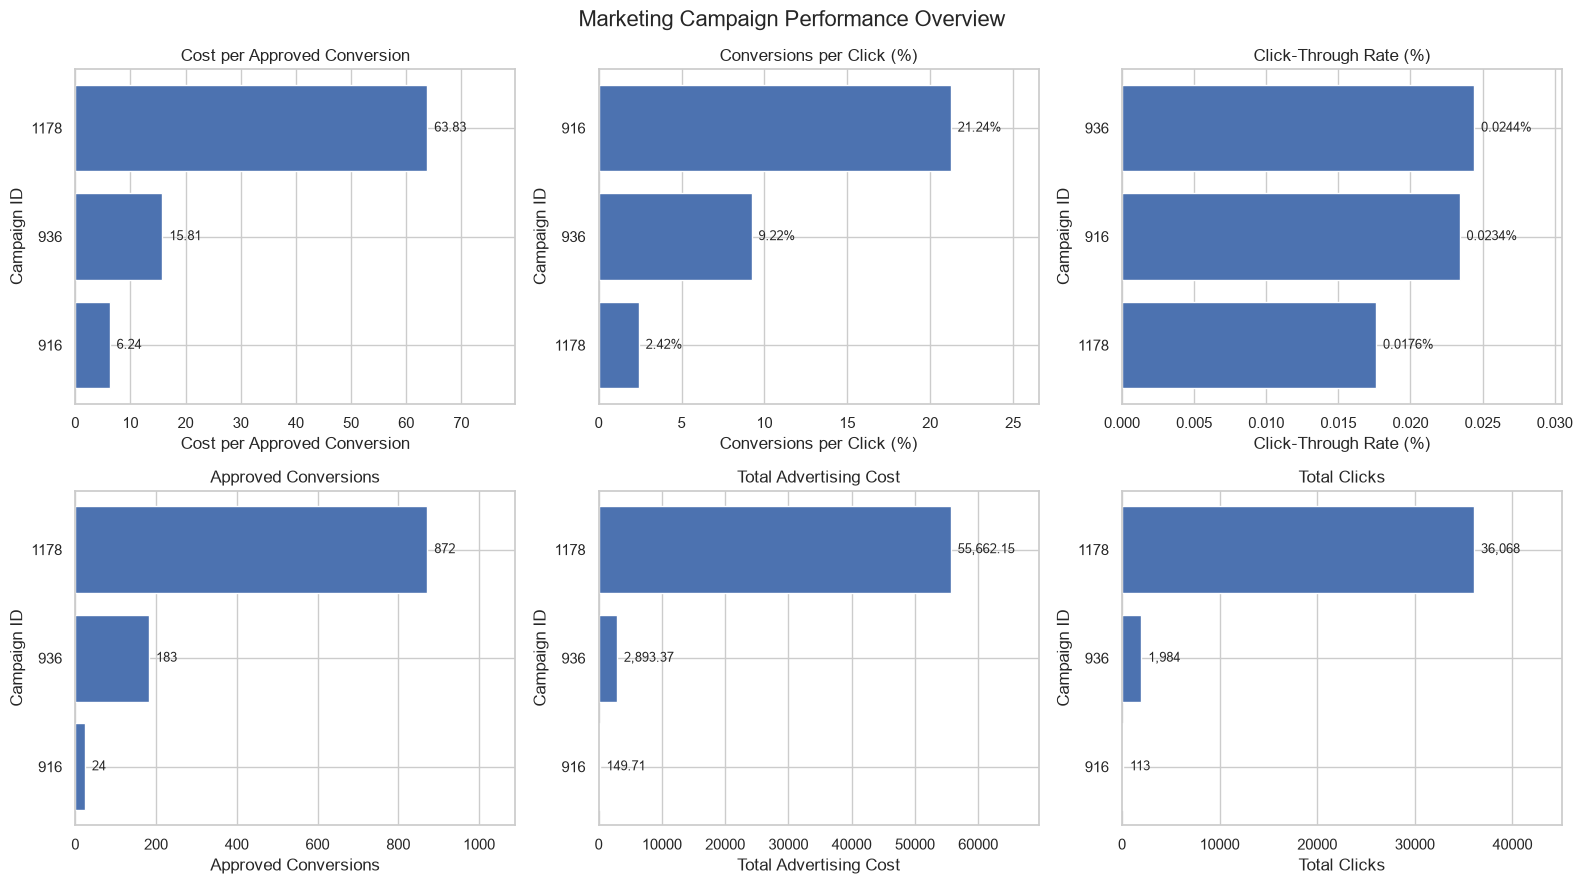

In [7]:
# Visualize campaign performance across six available metrics

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

metrics = [
    ("CPA", "Cost per Approved Conversion"),
    ("conv_rate", "Conversions per Click (%)"),
    ("CTR", "Click-Through Rate (%)"),
    ("conversions", "Approved Conversions"),
    ("cost", "Total Advertising Cost"),
    ("clicks", "Total Clicks")
]

for ax, (metric, title) in zip(axes.flat, metrics):

    values = agg[metric].copy()

    # Convert ratios to percentages for better readability
    if metric in ["conv_rate", "CTR"]:
        values = values * 100

    values = values.sort_values()

    ax.barh(
        values.index.astype(str),
        values.values
    )

    ax.set_title(title)
    ax.set_xlabel(title)
    ax.set_ylabel("Campaign ID")

    # Display values next to bars
    for i, value in enumerate(values.values):

        if metric == "CTR":
            label = f"{value:.4f}%"
        elif metric == "conv_rate":
            label = f"{value:.2f}%"
        elif metric in ["clicks", "conversions"]:
            label = f"{value:,.0f}"
        else:
            label = f"{value:,.2f}"

        ax.annotate(
            label,
            xy=(value, i),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=9
        )

    # Leave space for value labels
    ax.set_xlim(0, values.max() * 1.25)

plt.suptitle(
    "Marketing Campaign Performance Overview",
    fontsize=16
)

plt.tight_layout()

# Save visualization
plt.savefig(
    OUT / "group_metrics_overview.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

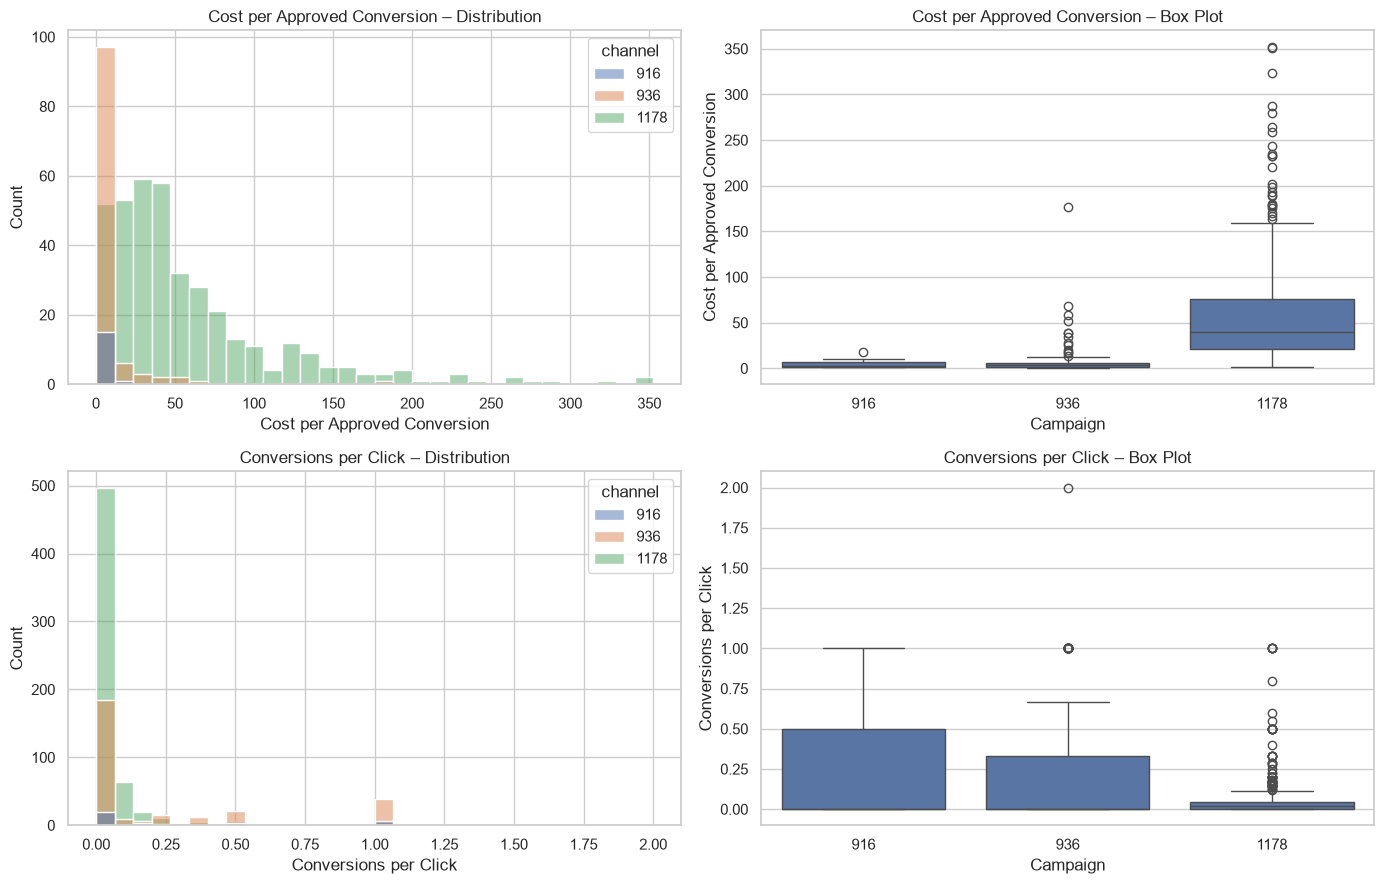


=== VALID OBSERVATIONS PER METRIC ===
         CPA  conv_rate
channel                
916       16         35
936      112        288
1178     385        613

=== CONVERSION-TO-CLICK RATIOS ABOVE 100% ===
1


In [8]:
# Calculate metrics for each advertising record
df["CPA"] = (
    df["cost"] / df["conversions"].replace(0, np.nan)
).where(df["cost"] > 0)

df["conv_rate"] = (
    df["conversions"] / df["clicks"].replace(0, np.nan)
)

df = df.replace([np.inf, -np.inf], np.nan)

# Prepare observations for plotting
paid = df[df["cost"] > 0].copy()

metrics = [
    ("CPA", "Cost per Approved Conversion"),
    ("conv_rate", "Conversions per Click")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for row, (metric, title) in enumerate(metrics):

    clean = df[["channel", metric]].dropna().copy()
    clean["channel"] = clean["channel"].astype(str)

    # Histogram: distribution of values
    sns.histplot(
        data=clean,
        x=metric,
        hue="channel",
        bins=30,
        alpha=0.5,
        ax=axes[row, 0]
    )

    axes[row, 0].set_title(f"{title} – Distribution")
    axes[row, 0].set_xlabel(title)

    # Box plot: median, spread and outliers
    sns.boxplot(
        data=clean,
        x="channel",
        y=metric,
        ax=axes[row, 1]
    )

    axes[row, 1].set_title(f"{title} – Box Plot")
    axes[row, 1].set_xlabel("Campaign")
    axes[row, 1].set_ylabel(title)

plt.tight_layout()

plt.savefig(
    OUT / "group_distributions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Check how many observations are usable
print("\n=== VALID OBSERVATIONS PER METRIC ===")
print(df.groupby("channel")[["CPA", "conv_rate"]].count())

print("\n=== CONVERSION-TO-CLICK RATIOS ABOVE 100% ===")
print((df["conv_rate"] > 1).sum())

In [9]:
# Summarize CPA distributions by campaign
cpa_spread = df.groupby("channel")["CPA"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    min="min",
    max="max"
)

# Coefficient of Variation
cpa_spread["CV"] = (
    cpa_spread["std"]
    / cpa_spread["mean"].replace(0, np.nan)
)

print("=== CPA DISTRIBUTION SUMMARY ===")
display(cpa_spread.round(3))

=== CPA DISTRIBUTION SUMMARY ===


,count,mean,median,std,min,max,CV
channel,,,,,,,
916,16,4.713,2.89,4.707,1.13,18.07,0.999
936,112,8.441,3.19,19.628,0.18,176.38,2.325
1178,385,58.863,39.73,58.011,1.49,352.45,0.986



**✍️ Key Insights – Marketing Performance Analysis**

**1. Best-performing campaigns**

- Campaign 916 has the lowest aggregate CPA (6.24) and the highest observed conversions-to-clicks ratio (21.24%).
- Campaign 936 achieves the highest CTR (0.0244%).
- Campaign 1178 generates the most approved conversions (872), but has the highest aggregate CPA (63.83).

**2. Variability and outliers**

- Campaign 936 has the highest relative CPA variability (CV = 2.325) among advertising records with approved conversions.
- Campaign 1178 has the highest absolute CPA standard deviation (58.011) and contains extreme CPA values reaching 352.45.
- The CPA distributions are strongly right-skewed, with several high-value outliers.

**3. Similarities between campaigns**

- Campaigns 916 and 936 have relatively similar median CPA values (2.89 vs. 3.19).
- Their aggregate CTR values are also close.
- Statistical significance cannot yet be determined from these descriptive results.

**4. Data and statistical limitations**

- Only 513 of 1,143 advertising records have defined individual CPA values. Records without approved conversions are excluded from the individual CPA distribution.
- Campaign 916 has only 16 valid individual CPA observations, limiting statistical power.
- Individual CPA means differ from aggregate campaign CPA because they represent different estimands.
- The dataset contains no daily observations, revenue information, or seven distinct marketing channels.
- Some approved conversions occur without recorded clicks, so conversions-to-clicks ratios cannot automatically be interpreted as purchase probabilities.
- Observational campaign differences do not establish causal performance advantages.

**Conclusion**

Campaign 916 appears most cost-efficient based on aggregate CPA, while campaign 1178 generates the highest conversion volume. However, differences in sample size, variability, attribution, and campaign scale mean that no definitive budget reallocation should be recommended before further statistical analysis.

## Part 2 — Pairwise comparisons (60–75 min)
### Step 4: t-tests + Cohen's d

For every **pair** of channels: is the gap in average daily CPA bigger than the day-to-day luck?

💡 **Hints:**
- `from itertools import combinations`: `combinations(groups, 2)` gives every pair once.
- Use **Welch's t-test**: `stats.ttest_ind(b, a, equal_var=False)`. Why Welch and not the default? Look at the test table in §4b.
- Cohen's d = (mean_b − mean_a) / √((var_a + var_b) / 2). Scale: < 0.2 negligible · < 0.5 small · < 0.8 medium · ≥ 0.8 large.

In [10]:
# Calculate Cohen's d
def cohens_d(a, b):
    mean_diff = np.mean(b) - np.mean(a)

    var_a = np.var(a, ddof=1)
    var_b = np.var(b, ddof=1)

    pooled_sd = np.sqrt((var_a + var_b) / 2)

    if pooled_sd == 0:
        return np.nan

    return mean_diff / pooled_sd


# Interpret the standardized effect size
def effect_label(d):
    if np.isnan(d):
        return "undefined"

    d = abs(d)

    if d < 0.2:
        return "negligible"
    elif d < 0.5:
        return "small"
    elif d < 0.8:
        return "medium"
    else:
        return "large"


# Perform all pairwise comparisons
def pairwise_ttests(data, metric):

    clean = data[
        ["channel", metric]
    ].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    # Keep valid zero conversion-to-click ratios.
    # CPA values are already NaN when undefined.
    clean = clean[clean[metric] >= 0]

    rows = []

    groups = sorted(clean["channel"].unique())

    for a, b in combinations(groups, 2):

        xa = clean.loc[
            clean["channel"] == a, metric
        ]

        xb = clean.loc[
            clean["channel"] == b, metric
        ]

        # Welch's t-test
        t, p = stats.ttest_ind(
            xb, xa, equal_var=False
        )

        # Difference: B minus A
        diff = xb.mean() - xa.mean()

        pct_diff = (
            diff / xa.mean() * 100
            if xa.mean() != 0 else np.nan
        )

        d = cohens_d(xa, xb)

        rows.append({
            "group_a": a,
            "group_b": b,
            "n_a": len(xa),
            "n_b": len(xb),
            "mean_a": xa.mean(),
            "mean_b": xb.mean(),
            "diff": diff,
            "pct_diff": pct_diff,
            "t_stat": t,
            "p_value": p,
            "cohens_d": d,
            "effect": effect_label(d),
            "significant": p < ALPHA
        })

    res = pd.DataFrame(rows)

    print(
        f"{metric}: {len(res)} comparisons, "
        f"{res['significant'].sum()} significant"
    )

    return res


# CPA comparisons
print("=== CPA PAIRWISE COMPARISONS ===")
cpa_res = pairwise_ttests(paid, "CPA")
display(cpa_res.round(4))


# Conversion-to-click ratio comparisons
print("\n=== CONVERSION RATIO PAIRWISE COMPARISONS ===")
cvr_t_res = pairwise_ttests(df, "conv_rate")
display(cvr_t_res.round(4))

=== CPA PAIRWISE COMPARISONS ===
CPA: 3 comparisons, 2 significant


,group_a,group_b,n_a,n_b,mean_a,mean_b,diff,pct_diff,t_stat,p_value,cohens_d,effect,significant
0,916,936,16,112,4.7125,8.4406,3.7281,79.1101,1.6973,0.0928,0.2612,small,False
1,916,1178,16,385,4.7125,58.8626,54.1501,1149.0738,17.0172,0.0000,1.3158,large,True
2,936,1178,112,385,8.4406,58.8626,50.4220,597.3775,14.4470,0.0000,1.1644,large,True



=== CONVERSION RATIO PAIRWISE COMPARISONS ===
conv_rate: 3 comparisons, 2 significant


,group_a,group_b,n_a,n_b,mean_a,mean_b,diff,pct_diff,t_stat,p_value,cohens_d,effect,significant
0,916,936,35,288,0.2571,0.2121,-0.045,-17.5153,-0.6678,0.5079,-0.1218,negligible,False
1,916,1178,35,613,0.2571,0.0521,-0.205,-79.7204,-3.1927,0.0030,-0.7286,medium,True
2,936,1178,288,613,0.2121,0.0521,-0.160,-75.4141,-7.3389,0.0000,-0.5947,medium,True


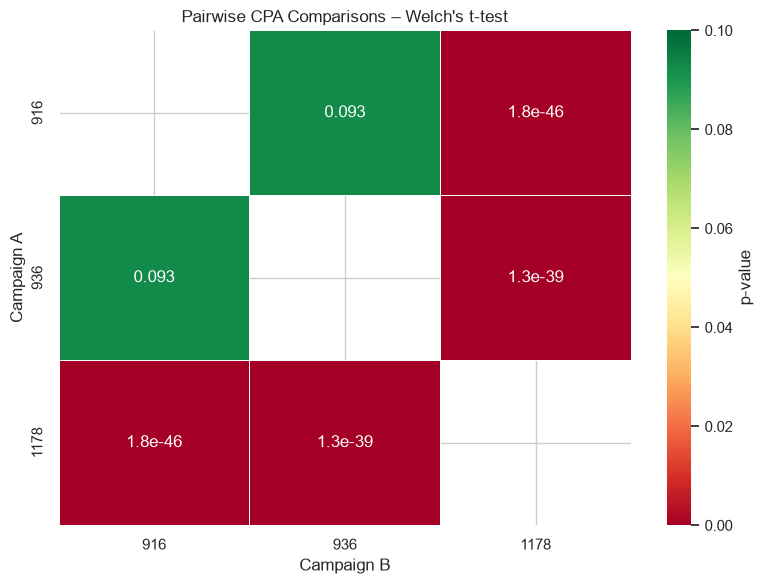

In [11]:
# Create a p-value matrix for CPA comparisons
groups = sorted(df["channel"].unique())

p_matrix = pd.DataFrame(
    1.0,
    index=groups,
    columns=groups
)

# Fill matrix symmetrically with p-values
for _, row in cpa_res.iterrows():
    a = int(row["group_a"])
    b = int(row["group_b"])
    p = row["p_value"]

    p_matrix.loc[a, b] = p
    p_matrix.loc[b, a] = p

# Plot heatmap
plt.figure(figsize=(8, 6))

# Hide comparisons of campaigns with themselves
mask = np.eye(len(p_matrix), dtype=bool)

sns.heatmap(
    p_matrix,
    mask=mask,
    annot=True,
    fmt=".2g",
    cmap="RdYlGn",
    vmin=0,
    vmax=0.10,
    linewidths=0.5,
    cbar_kws={"label": "p-value"}
)

plt.title("Pairwise CPA Comparisons – Welch's t-test")
plt.xlabel("Campaign B")
plt.ylabel("Campaign A")

plt.tight_layout()

# Save figure
plt.savefig(
    OUT / "metric_comparison_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

**✍️ Which channels differ significantly? Which pairs can't be told apart?**

💡 **Remember (§3):** a big p-value means **"can't tell"**, not "no difference".

### Step 5: Fisher's exact test on conversions (30–35 min)

Each click either converts or doesn't: **right/wrong data**, so Fisher's exact test (§4b).

```
[[conversions_A, non_conversions_A],
 [conversions_B, non_conversions_B]]
```

In [12]:
# Fisher's exact test: ad-level purchase success
# An ad is successful if it generated >= 1 approved purchase.

df["ad_has_purchase"] = df["conversions"] > 0

# Aggregate successful and unsuccessful ads per campaign
conv = df.groupby("channel").agg(
    total_ads=("ad_id", "size"),
    ads_with_purchase=("ad_has_purchase", "sum")
)

conv["ads_without_purchase"] = (
    conv["total_ads"] - conv["ads_with_purchase"]
)

conv["ad_success_rate"] = (
    conv["ads_with_purchase"] / conv["total_ads"]
)

print("=== AD-LEVEL PURCHASE SUCCESS ===")
display(conv.round(4))

# Pairwise Fisher's exact tests
rows = []

for a, b in combinations(sorted(conv.index), 2):

    table = [
        [
            int(conv.loc[a, "ads_with_purchase"]),
            int(conv.loc[a, "ads_without_purchase"])
        ],
        [
            int(conv.loc[b, "ads_with_purchase"]),
            int(conv.loc[b, "ads_without_purchase"])
        ]
    ]

    odds_ratio, p = fisher_exact(
        table, alternative="two-sided"
    )

    rate_a = conv.loc[a, "ad_success_rate"]
    rate_b = conv.loc[b, "ad_success_rate"]

    diff_pp = (rate_b - rate_a) * 100

    pct_diff = (
        (rate_b - rate_a) / rate_a * 100
        if rate_a > 0 else np.nan
    )

    rows.append({
        "group_a": a,
        "group_b": b,
        "rate_a": rate_a,
        "rate_b": rate_b,
        "diff_pp": diff_pp,
        "pct_diff": pct_diff,
        "odds_ratio": odds_ratio,
        "p_value": p,
        "significant": p < ALPHA
    })

fisher_res = pd.DataFrame(rows)

print("\n=== FISHER'S EXACT TEST RESULTS ===")
display(fisher_res.round(4))

fisher_res.to_csv(
    OUT / "fisher_ad_level_results.csv",
    index=False
)

=== AD-LEVEL PURCHASE SUCCESS ===


,total_ads,ads_with_purchase,ads_without_purchase,ad_success_rate
channel,,,,
916,54,24,30,0.4444
936,464,172,292,0.3707
1178,625,388,237,0.6208



=== FISHER'S EXACT TEST RESULTS ===


,group_a,group_b,rate_a,rate_b,diff_pp,pct_diff,odds_ratio,p_value,significant
0,916,936,0.4444,0.3707,-7.3755,-16.5948,1.3581,0.3021,False
1,916,1178,0.4444,0.6208,17.6356,39.6800,0.4887,0.0133,True
2,936,1178,0.3707,0.6208,25.0110,67.4716,0.3598,0.0000,True


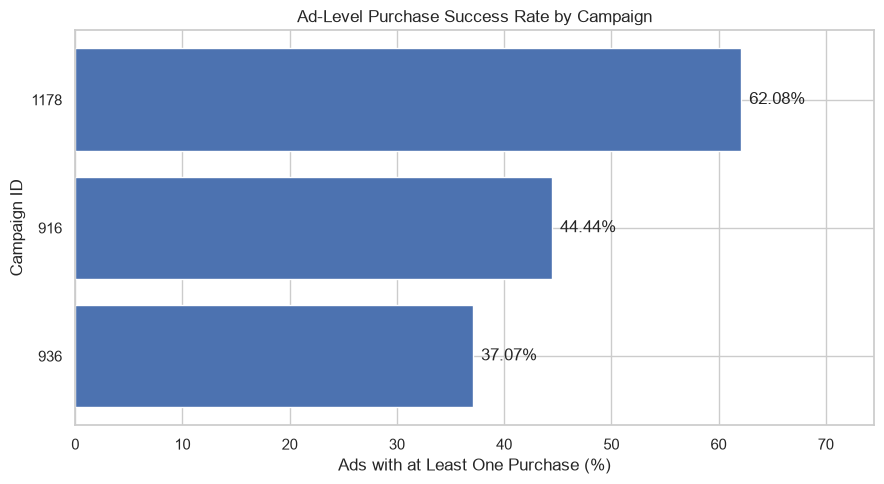

In [13]:
# Visualize ad-level purchase success rates

success_rates = (
    conv["ad_success_rate"]
    .sort_values(ascending=True) * 100
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    success_rates.index.astype(str),
    success_rates.values
)

# Add percentage labels
for bar, value in zip(bars, success_rates.values):
    ax.annotate(
        f"{value:.2f}%",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(6, 0),
        textcoords="offset points",
        va="center"
    )

ax.set_title(
    "Ad-Level Purchase Success Rate by Campaign"
)
ax.set_xlabel("Ads with at Least One Purchase (%)")
ax.set_ylabel("Campaign ID")
ax.set_xlim(0, success_rates.max() * 1.2)

plt.tight_layout()

plt.savefig(
    OUT / "rate_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

**✍️ Answer:**
**Step 4 – Interpretation of Welch's t-tests**

- Campaigns 916 and 1178 show a statistically significant
  difference in mean CPA (p < 0.001, Cohen's d = 1.32).
- Campaigns 936 and 1178 also differ significantly
  (p < 0.001, Cohen's d = 1.16).
- Campaigns 916 and 936 do not show a statistically
  significant difference (p = 0.0928).

These are uncorrected p-values.

The tests only include advertisements with defined CPA
values. Therefore, they do not measure the full economic
performance of all advertisements.

Non-significance does not establish equivalence.

**Step 5 – Fisher's Exact Test Interpretation**

1. Statistically significant differences:

- Campaign 1178 has a significantly higher ad-level
  purchase success rate than campaign 916 (p = 0.0133).
- Campaign 1178 also performs significantly better than
  campaign 936 (p < 0.001).
- Campaigns 916 and 936 do not differ significantly
  (p = 0.3021).

2. Practical significance:

The differences in ad-level purchase success rates are
17.64 percentage points (1178 vs. 916) and
25.01 percentage points (1178 vs. 936).

These are substantial observed differences. However,
advertisements have different spending and impression
levels, which may influence their probability of
generating at least one purchase.

3. Fisher vs. t-test:

Both methods identify significant differences involving
campaign 1178, but not between 916 and 936.

However, the tests measure different outcomes:

- Welch's t-test compares mean CPA or mean
  conversion-to-click ratios per eligible ad record.
- Fisher's exact test compares the proportion of ad
  records with at least one approved purchase.

Therefore, the results are not directly interchangeable.

All findings remain exploratory and have not yet been
adjusted for multiple comparisons.

## Part 3 — Multiple comparisons correction (45–60 min)
### Step 6: Bonferroni and Benjamini-Hochberg

💡 **Hints (§8 of the statistics notebook):**
- Bonferroni: significant if `p < ALPHA / number_of_tests`
- BH: `false_discovery_control(p_values, method="bh")` returns **adjusted** p-values; significant if adjusted < ALPHA

In [14]:
# Define the three comparison families
families = {
    "CPA (Welch t-test)": cpa_res,
    "Conversion/click ratio (t-test)": cvr_t_res,
    "Ad purchase success (Fisher)": fisher_res
}

# Count tests and calculate expected false positives
total_tests = sum(len(res) for res in families.values())

expected_false_positives = total_tests * ALPHA

print("=== MULTIPLE COMPARISONS OVERVIEW ===")
print(f"Total tests: {total_tests}")
print(f"Alpha: {ALPHA}")
print(
    "Expected false positives under the global null: "
    f"{expected_false_positives:.2f}"
)

# Apply corrections separately to each family
rows = []

for name, res in families.items():

    m = len(res)
    p_values = res["p_value"].astype(float).to_numpy()

    # Bonferroni correction
    alpha_bonferroni = ALPHA / m

    res["significant_bonferroni"] = (
        p_values < alpha_bonferroni
    )

    # Benjamini-Hochberg FDR correction
    res["p_value_fdr"] = false_discovery_control(
        p_values,
        method="bh"
    )

    res["significant_fdr"] = (
        res["p_value_fdr"] < ALPHA
    )

    # Store summary
    rows.append({
        "family": name,
        "tests": m,
        "uncorrected": int((p_values < ALPHA).sum()),
        "Bonferroni": int(
            res["significant_bonferroni"].sum()
        ),
        "BH-FDR": int(
            res["significant_fdr"].sum()
        )
    })

# Create summary table
correction_summary = pd.DataFrame(rows).set_index("family")

print("\n=== CORRECTION SUMMARY ===")
display(correction_summary)

=== MULTIPLE COMPARISONS OVERVIEW ===
Total tests: 9
Alpha: 0.05
Expected false positives under the global null: 0.45

=== CORRECTION SUMMARY ===


,tests,uncorrected,Bonferroni,BH-FDR
family,,,,
CPA (Welch t-test),3,2,2,2
Conversion/click ratio (t-test),3,2,2,2
Ad purchase success (Fisher),3,2,2,2


In [15]:
# Sensitivity analysis: correct all nine tests together

all_tests = pd.concat([
    cpa_res.assign(metric="CPA"),
    cvr_t_res.assign(metric="Conversion-to-Click Ratio"),
    fisher_res.assign(metric="Ad Purchase Success")
], ignore_index=True)

# Keep relevant information
all_tests = all_tests[
    ["metric", "group_a", "group_b", "p_value"]
].copy()

# Total number of comparisons
m = len(all_tests)

# Global Bonferroni correction
all_tests["p_bonferroni"] = np.minimum(
    all_tests["p_value"] * m, 1.0
)

all_tests["significant_bonferroni"] = (
    all_tests["p_bonferroni"] < ALPHA
)

# Global Benjamini-Hochberg correction
all_tests["p_fdr"] = false_discovery_control(
    all_tests["p_value"].to_numpy(),
    method="bh"
)

all_tests["significant_fdr"] = (
    all_tests["p_fdr"] < ALPHA
)

print("=== GLOBAL CORRECTION: ALL NINE TESTS ===")
print(f"Number of tests: {m}")
print(f"Bonferroni threshold: {ALPHA / m:.6f}")

display(
    all_tests.sort_values("p_value")
)

print("\n=== GLOBAL SIGNIFICANCE COUNTS ===")
print(
    "Bonferroni:",
    all_tests["significant_bonferroni"].sum()
)
print(
    "BH-FDR:",
    all_tests["significant_fdr"].sum()
)

=== GLOBAL CORRECTION: ALL NINE TESTS ===
Number of tests: 9
Bonferroni threshold: 0.005556


,metric,group_a,group_b,p_value,p_bonferroni,significant_bonferroni,p_fdr,significant_fdr
1,CPA,916,1178,1.829061e-46,1.646155e-45,True,1.646155e-45,True
2,CPA,936,1178,1.307053e-39,1.176348e-38,True,5.881740e-39,True
8,Ad Purchase Success,936,1178,2.672877e-16,2.405589e-15,True,8.018632e-16,True
5,Conversion-to-Click Ratio,936,1178,1.807764e-12,1.626988e-11,True,4.067469e-12,True
4,Conversion-to-Click Ratio,916,1178,3.009310e-03,2.708379e-02,True,5.416759e-03,True
7,Ad Purchase Success,916,1178,1.331993e-02,1.198794e-01,False,1.997990e-02,True
0,CPA,916,936,9.277109e-02,8.349398e-01,False,1.192771e-01,False
6,Ad Purchase Success,916,936,3.021411e-01,1.000000e+00,False,3.399088e-01,False
3,Conversion-to-Click Ratio,916,936,5.079465e-01,1.000000e+00,False,5.079465e-01,False



=== GLOBAL SIGNIFICANCE COUNTS ===
Bonferroni: 5
BH-FDR: 6


=== LOST SIGNIFICANCE: GLOBAL BONFERRONI ===


,metric,group_a,group_b,p_value,p_bonferroni
7,Ad Purchase Success,916,1178,0.01332,0.119879



=== CORRECTION COMPARISON ===


,uncorrected,Bonferroni,BH-FDR
family,,,
CPA (Welch t-test),2,2,2
Conversion/click ratio (t-test),2,2,2
Ad purchase success (Fisher),2,2,2
All 9 (global),6,5,6


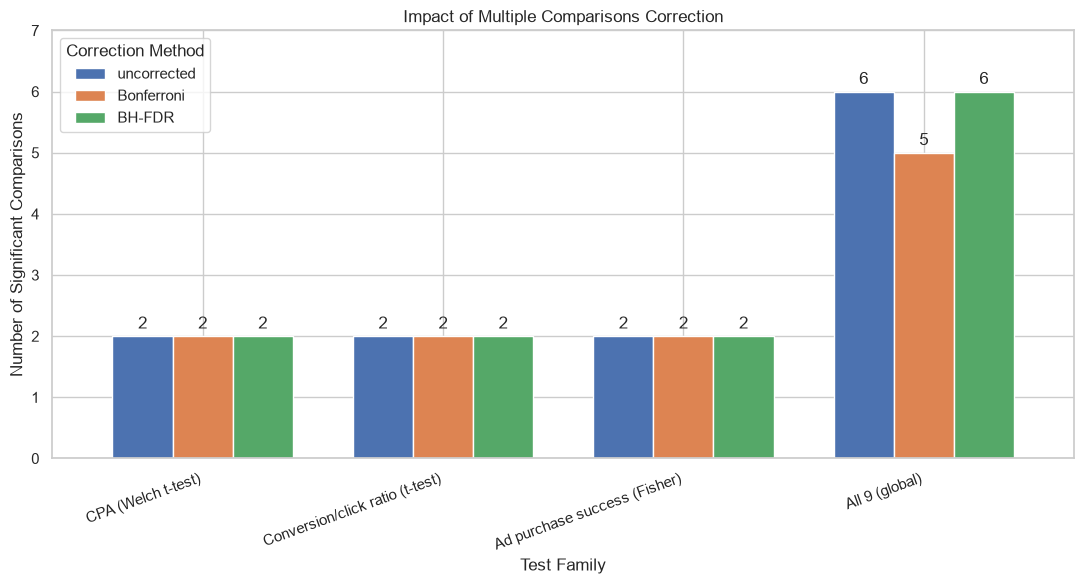

In [16]:
# Identify comparisons that lose significance

lost_global_bonf = all_tests.loc[
    (all_tests["p_value"] < ALPHA)
    & (~all_tests["significant_bonferroni"]),
    ["metric", "group_a", "group_b",
     "p_value", "p_bonferroni"]
]

print("=== LOST SIGNIFICANCE: GLOBAL BONFERRONI ===")
display(lost_global_bonf)

# Compare separate-family corrections with global corrections
plot_data = correction_summary[
    ["uncorrected", "Bonferroni", "BH-FDR"]
].copy()

plot_data.loc["All 9 (global)"] = [
    int((all_tests["p_value"] < ALPHA).sum()),
    int(all_tests["significant_bonferroni"].sum()),
    int(all_tests["significant_fdr"].sum())
]

print("\n=== CORRECTION COMPARISON ===")
display(plot_data)

# Create grouped bar chart
ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("Impact of Multiple Comparisons Correction")
ax.set_ylabel("Number of Significant Comparisons")
ax.set_xlabel("Test Family")
ax.set_ylim(0, 7)
ax.set_xticklabels(
    plot_data.index,
    rotation=20,
    ha="right"
)

# Add labels to bars
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.legend(title="Correction Method")
plt.tight_layout()

plt.savefig(
    OUT / "correction_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

**✍️ Answer:**

### Step 6 – Multiple Comparisons: Interpretation

**1. How many significant results disappeared after correction?**

We performed nine pairwise statistical tests across three metric families.

Initially, six comparisons were statistically significant at α = 0.05.

When applying Bonferroni and Benjamini-Hochberg (BH-FDR) separately within each metric family, all six results remained significant.

However, when correcting all nine tests together:

- Bonferroni: 5 of 9 comparisons remained significant.
- BH-FDR: 6 of 9 comparisons remained significant.

The ad-level purchase success comparison between campaigns 916 and 1178 lost significance under global Bonferroni correction (adjusted p = 0.1199).

This does not prove that the original finding was a false positive.

**2. Which correction is more appropriate for a budget decision, and why?**

For a high-stakes budget allocation decision, Bonferroni is a conservative choice because it controls the family-wise error rate, reducing the risk of making at least one false discovery.

BH-FDR is useful for exploratory analysis because it controls the expected false discovery rate and generally retains greater statistical power.

We report both methods, using the global Bonferroni results as a conservative sensitivity check.

**3. What does this mean for moving budget?**

The results provide statistical evidence of performance differences, particularly between campaign 1178 and the other campaigns.

However, statistical significance alone does not justify budget reallocation.

Important limitations include:

- The data covers three advertising campaigns rather than seven marketing channels.
- No revenue data is available to calculate ROAS or profit.
- Advertising records differ in spending and impressions.
- Some CPA comparisons exclude advertisements without purchases.
- The observational data cannot establish causal performance advantages.

Therefore, we should avoid recommending immediate large-scale budget shifts solely based on these results.

A cautious approach would prioritize additional data collection, controlled experiments, and validation of campaign scalability before reallocating substantial marketing resources.


## Part 4 — Power analysis (30–45 min)
### Step 7: Do we have enough data?

**Power** = the chance of catching a difference that is **really** there (§5). Simulate many experiments where you **know** the truth:
- channel A: daily CPA ~ normal(mean = `base_cpa`, std = 15% of `base_cpa`)
- channel B: the same, but mean = `base_cpa × (1 + true_diff_pct)`
- cap low values at 50% of `base_cpa` (`np.maximum(x, 0.5 * base_cpa)`)
- t-test → count how often p < 0.05

💡 **Speed hint:** draw all simulations at once with shape `(n_sim, n_days)` and use `stats.ttest_ind(a, b, axis=1)`. A plain loop also works, but use `n_sim=300` then.

=== POWER ANALYSIS ===
Baseline CPA: 15.81


effect_size_pct,5.0,10.0,15.0,20.0
n_days,,,,
30,0.240,0.701,0.948,0.997
60,0.431,0.945,1.000,1.000
90,0.585,0.992,1.000,1.000
120,0.756,0.999,1.000,1.000
180,0.884,1.000,1.000,1.000


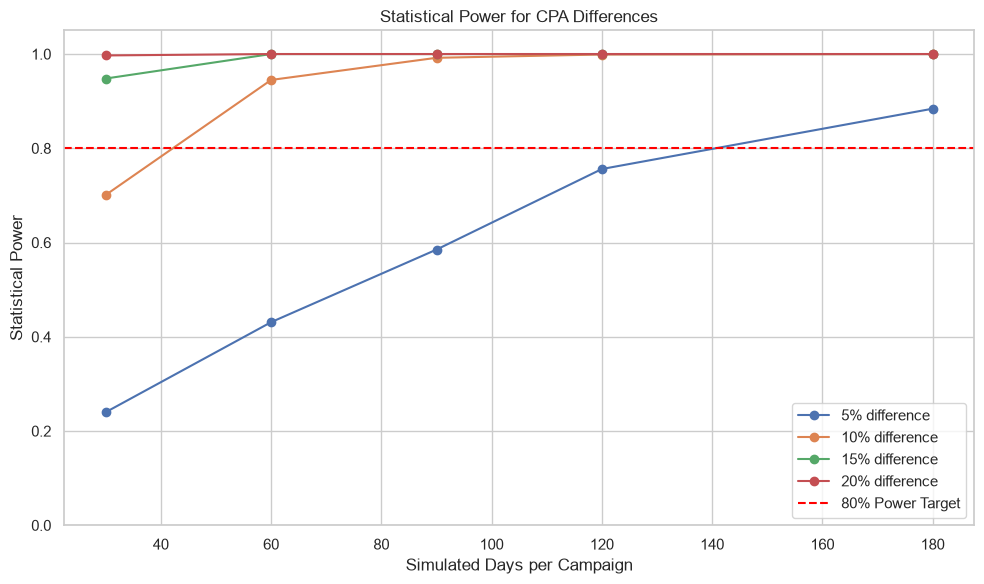

In [17]:
# Simulate statistical power for CPA comparisons

def empirical_power_cpa(
    true_diff_pct,
    base_cpa,
    n_days,
    n_sim=1000,
    alpha=0.05
):
    # Fixed seed for reproducible simulations
    simulation_rng = np.random.default_rng(42)

    # Assumed standard deviation: 15% of baseline CPA
    std = base_cpa * 0.15

    # Simulate CPA values for two campaigns
    a = simulation_rng.normal(
        loc=base_cpa,
        scale=std,
        size=(n_sim, n_days)
    )

    b = simulation_rng.normal(
        loc=base_cpa * (1 + true_diff_pct),
        scale=std,
        size=(n_sim, n_days)
    )

    # Prevent unrealistically low CPA values
    a = np.maximum(a, 0.5 * base_cpa)
    b = np.maximum(b, 0.5 * base_cpa)

    # Perform Welch's t-test for all simulations
    p_values = stats.ttest_ind(
        a, b,
        axis=1,
        equal_var=False
    ).pvalue

    # Power = proportion of significant tests
    power = np.mean(p_values < alpha)

    return float(power)


# Baseline: median aggregate CPA across our campaigns
BASE_CPA = float(agg["CPA"].dropna().median())

effects = [0.05, 0.10, 0.15, 0.20]
days = [30, 60, 90, 120, 180]

# Calculate power for every combination
results = []

for effect in effects:
    for n_days in days:

        power = empirical_power_cpa(
            true_diff_pct=effect,
            base_cpa=BASE_CPA,
            n_days=n_days
        )

        results.append({
            "effect_size_pct": effect * 100,
            "n_days": n_days,
            "power": power
        })

power_df = pd.DataFrame(results)

print("=== POWER ANALYSIS ===")
print(f"Baseline CPA: {BASE_CPA:.2f}")

display(
    power_df.pivot(
        index="n_days",
        columns="effect_size_pct",
        values="power"
    ).round(3)
)


# Plot power curves
plt.figure(figsize=(10, 6))

for effect, group in power_df.groupby("effect_size_pct"):

    plt.plot(
        group["n_days"],
        group["power"],
        marker="o",
        label=f"{effect:.0f}% difference"
    )

# Target power
plt.axhline(
    y=0.8,
    color="red",
    linestyle="--",
    label="80% Power Target"
)

plt.title("Statistical Power for CPA Differences")
plt.xlabel("Simulated Days per Campaign")
plt.ylabel("Statistical Power")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    OUT / "power_analysis_cpa.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [18]:
# Determine the minimum tested sample size for 80% power

TARGET_POWER = 0.80
REFERENCE_N = 90  # Hypothetical scenario, not actual days

minimum_samples = []

for effect in sorted(power_df["effect_size_pct"].unique()):

    subset = power_df[
        power_df["effect_size_pct"] == effect
    ].sort_values("n_days")

    # Find tested sample sizes with at least 80% power
    sufficient = subset[
        subset["power"] >= TARGET_POWER
    ]

    min_n = (
        int(sufficient["n_days"].iloc[0])
        if not sufficient.empty
        else np.nan
    )

    # Power at the hypothetical 90-observation reference
    power_90 = subset.loc[
        subset["n_days"] == REFERENCE_N,
        "power"
    ].iloc[0]

    minimum_samples.append({
        "effect_size_pct": effect,
        "min_tested_n_for_80_power": min_n,
        "power_at_90": power_90,
        "90_observation_scenario": (
            "sufficient" if power_90 >= TARGET_POWER
            else "insufficient"
        )
    })

sample_size_df = pd.DataFrame(minimum_samples)

print("=== MINIMUM SAMPLE SIZE ASSESSMENT ===")
display(sample_size_df)

print(
    "\nNote: These are hypothetical independent "
    "observations, not verified campaign days."
)

=== MINIMUM SAMPLE SIZE ASSESSMENT ===


,effect_size_pct,min_tested_n_for_80_power,power_at_90,90_observation_scenario
0,5.0,180,0.585,insufficient
1,10.0,60,0.992,sufficient
2,15.0,30,1.000,sufficient
3,20.0,30,1.000,sufficient



Note: These are hypothetical independent observations, not verified campaign days.


In [19]:
# Assess actual CPA sample sizes and variability
# for comparisons significant after BH-FDR correction.

significant_cpa = cpa_res[
    cpa_res["significant_fdr"]
].copy()

assessment_rows = []

for _, row in significant_cpa.iterrows():

    a = int(row["group_a"])
    b = int(row["group_b"])

    # Actual valid CPA observations
    xa = df.loc[
        (df["channel"] == a) & df["CPA"].notna(),
        "CPA"
    ]

    xb = df.loc[
        (df["channel"] == b) & df["CPA"].notna(),
        "CPA"
    ]

    mean_a = xa.mean()
    mean_b = xb.mean()

    # Calculate absolute percentage difference
    # relative to the smaller observed mean
    smaller_mean = min(mean_a, mean_b)

    observed_diff_pct = (
        abs(mean_b - mean_a) / smaller_mean * 100
        if smaller_mean > 0 else np.nan
    )

    assessment_rows.append({
        "group_a": a,
        "group_b": b,
        "n_a": len(xa),
        "n_b": len(xb),
        "mean_cpa_a": mean_a,
        "mean_cpa_b": mean_b,
        "std_a": xa.std(),
        "std_b": xb.std(),
        "observed_diff_pct": observed_diff_pct,
        "fdr_adjusted_p": row["p_value_fdr"]
    })

actual_data_assessment = pd.DataFrame(assessment_rows)

print("=== ACTUAL CPA DATA ADEQUACY ===")
display(actual_data_assessment.round(3))

print(
    "\nNOTE: Sample sizes represent ad records with "
    "approved purchases, not campaign days."
)

print(
    "Observed effects and standard deviations are "
    "descriptive estimates, not guaranteed future values."
)

=== ACTUAL CPA DATA ADEQUACY ===


,group_a,group_b,n_a,n_b,mean_cpa_a,mean_cpa_b,std_a,std_b,observed_diff_pct,fdr_adjusted_p
0,916,1178,16,385,4.713,58.863,4.707,58.011,1149.074,0.0
1,936,1178,112,385,8.441,58.863,19.628,58.011,597.378,0.0



NOTE: Sample sizes represent ad records with approved purchases, not campaign days.
Observed effects and standard deviations are descriptive estimates, not guaranteed future values.


In [20]:
# Prospective sample size planning using observed CPA variability
# Approximation for two independent groups of equal size

TARGET_POWER = 0.80
EFFECTS = [0.05, 0.10, 0.20]

z_alpha = stats.norm.ppf(1 - ALPHA / 2)
z_power = stats.norm.ppf(TARGET_POWER)

planning_rows = []

for channel, row in cpa_spread.iterrows():

    mean_cpa = row["mean"]
    std_cpa = row["std"]

    for effect in EFFECTS:

        # Minimum difference we want to detect
        target_difference = mean_cpa * effect

        # Approximate required sample size PER group
        required_n = np.ceil(
            2 * (z_alpha + z_power) ** 2
            * (std_cpa / target_difference) ** 2
        )

        planning_rows.append({
            "campaign": channel,
            "target_difference_pct": effect * 100,
            "observed_cv": std_cpa / mean_cpa,
            "required_n_per_group": int(required_n)
        })

realistic_sample_plan = pd.DataFrame(planning_rows)

print("=== SAMPLE SIZE PLANNING WITH OBSERVED VARIABILITY ===")

display(
    realistic_sample_plan.pivot(
        index="campaign",
        columns="target_difference_pct",
        values="required_n_per_group"
    )
)

print(
    "\nNote: Approximate planning values for independent "
    "CPA observations, not campaign days."
)
print(
    "Assumes equal group sizes, approximate normality, "
    "and variability similar to the observed data."
)

=== SAMPLE SIZE PLANNING WITH OBSERVED VARIABILITY ===


target_difference_pct,5.0,10.0,20.0
campaign,,,
916,6264,1566,392
936,33957,8490,2123
1178,6099,1525,382



Note: Approximate planning values for independent CPA observations, not campaign days.
Assumes equal group sizes, approximate normality, and variability similar to the observed data.


**✍️ Answer:**

### Step 7 – Power Analysis: Interpretation

**1. What size of CPA difference can your data detect reliably?**

Under the hypothetical simulation assumptions (independent, approximately normally distributed daily CPA values with a standard deviation of 15% of baseline CPA), 90 observations per campaign provide:

- 58.5% power to detect a 5% difference.
- 99.2% power to detect a 10% difference.
- Approximately 100% power to detect differences of 15% or 20%.

Therefore, the hypothetical 90-observation design is adequate for detecting differences of around 10% or larger, but not a 5% difference at the target of 80% power.

However, the actual dataset contains aggregated advertising records rather than daily observations. Its CPA distributions show substantially higher variability.

Consequently, these simulated power estimates cannot be directly applied to the observed campaigns.

**2. How many days would you need to detect a 5% difference?**

In the initial simulation, 180 independent observations per campaign were the smallest tested sample size achieving at least 80% power for a 5% CPA difference.

This does not establish an exact minimum of 180 days.

Using the observed CPA variability, a separate approximate sample size calculation estimated the following requirements for detecting a 5% difference:

- Campaign 916: 6,264 observations per group.
- Campaign 936: 33,957 observations per group.
- Campaign 1178: 6,099 observations per group.

These estimates assume equal-sized independent samples and approximately normal sampling distributions.

They must not be interpreted as numbers of calendar days. The dataset contains no dates, and CPA was only defined for advertising records with approved purchases.

A reliable future test would require a prospective design using representative data, including advertising records without purchases.

**3. Do non-significant results indicate no difference or not enough data?**

The CPA comparison between campaigns 916 and 936 was not statistically significant (p = 0.0928).

This does not establish that the campaigns perform equally.

Only 16 advertising records from campaign 916 had defined individual CPA values, compared with 112 from campaign 936.

The limited sample size, unequal variances, and right-skewed distributions create substantial uncertainty.

Therefore, the correct conclusion is that the available analysis does not provide sufficient evidence to establish a mean CPA difference.

Further data collection and a more appropriate prospective evaluation design would be needed before drawing stronger conclusions.

**Overall conclusion**

Statistical power depends strongly on effect size, sample size, and variability.

The initial simulation illustrates how relatively stable data can make moderate CPA differences easier to detect.

The observed advertising data is much more variable, making small performance differences harder to identify reliably.

Power calculations alone cannot resolve the dataset's attribution issues, selection bias, missing time information, or lack of causal identification.


## Part 5 — Business recommendations (30–45 min)
### Step 8: From statistics to a decision

In [21]:
# Summarize statistically significant findings
# using BH-FDR corrected results

# 1. Significant CPA differences
cpa_sig = cpa_res[
    cpa_res["significant_fdr"]
].copy()

cpa_sig["cheaper_campaign"] = np.where(
    cpa_sig["mean_a"] < cpa_sig["mean_b"],
    cpa_sig["group_a"],
    cpa_sig["group_b"]
)

cpa_sig["absolute_cpa_difference"] = abs(
    cpa_sig["mean_b"] - cpa_sig["mean_a"]
)

cpa_summary = cpa_sig[[
    "group_a",
    "group_b",
    "cheaper_campaign",
    "absolute_cpa_difference",
    "cohens_d",
    "p_value_fdr"
]].copy()

print("=== SIGNIFICANT CPA FINDINGS ===")
display(cpa_summary)


# 2. Significant ad-level purchase success differences
fisher_sig = fisher_res[
    fisher_res["significant_fdr"]
].copy()

fisher_sig["higher_success_campaign"] = np.where(
    fisher_sig["rate_a"] > fisher_sig["rate_b"],
    fisher_sig["group_a"],
    fisher_sig["group_b"]
)

fisher_sig["absolute_difference_pp"] = abs(
    fisher_sig["diff_pp"]
)

fisher_summary = fisher_sig[[
    "group_a",
    "group_b",
    "higher_success_campaign",
    "absolute_difference_pp",
    "p_value_fdr"
]].copy()

print("\n=== SIGNIFICANT AD SUCCESS FINDINGS ===")
display(fisher_summary)


# Save findings
cpa_summary.to_csv(
    OUT / "significant_cpa_findings.csv",
    index=False
)

fisher_summary.to_csv(
    OUT / "significant_ad_success_findings.csv",
    index=False
)

=== SIGNIFICANT CPA FINDINGS ===


,group_a,group_b,cheaper_campaign,absolute_cpa_difference,cohens_d,p_value_fdr
1,916,1178,916,54.150104,1.315758,5.487184e-46
2,936,1178,936,50.422039,1.164355,1.960580e-39



=== SIGNIFICANT AD SUCCESS FINDINGS ===


,group_a,group_b,higher_success_campaign,absolute_difference_pp,p_value_fdr
1,916,1178,1178,17.635556,1.997990e-02
2,936,1178,1178,25.011034,8.018632e-16


In [22]:
# Bootstrap confidence intervals for aggregate CPA
# Resample complete ad records, including ads without purchases.

def bootstrap_ci(data, n_bootstrap=1000, ci_level=0.95):

    rng_boot = np.random.default_rng(42)

    values = data[["cost", "conversions"]].to_numpy(
        dtype=float
    )

    n = len(values)
    bootstrap_cpas = []

    for _ in range(n_bootstrap):

        # Resample complete advertising records
        indices = rng_boot.integers(0, n, size=n)
        sample = values[indices]

        total_cost = sample[:, 0].sum()
        total_conversions = sample[:, 1].sum()

        # CPA is undefined if no purchases occur
        if total_conversions > 0:
            bootstrap_cpas.append(
                total_cost / total_conversions
            )

    if not bootstrap_cpas:
        return np.nan, np.nan

    alpha = 1 - ci_level

    ci_low, ci_high = np.quantile(
        bootstrap_cpas,
        [alpha / 2, 1 - alpha / 2]
    )

    return ci_low, ci_high


# Calculate confidence intervals for each campaign
ci_rows = []

for channel, group in df.groupby("channel"):

    total_cost = group["cost"].sum()
    total_conversions = group["conversions"].sum()

    aggregate_cpa = (
        total_cost / total_conversions
        if total_conversions > 0 else np.nan
    )

    ci_low, ci_high = bootstrap_ci(group)

    ci_rows.append({
        "channel": channel,
        "observations": len(group),
        "aggregate_CPA": aggregate_cpa,
        "CI_95_low": ci_low,
        "CI_95_high": ci_high
    })

cpa_ci = pd.DataFrame(ci_rows)

print("=== BOOTSTRAP 95% CONFIDENCE INTERVALS ===")
display(cpa_ci.round(3))

# Save the results
cpa_ci.to_csv(
    OUT / "cpa_bootstrap_ci.csv",
    index=False
)

=== BOOTSTRAP 95% CONFIDENCE INTERVALS ===


,channel,observations,aggregate_CPA,CI_95_low,CI_95_high
0,916,54,6.238,3.919,9.728
1,936,464,15.811,12.048,20.938
2,1178,625,63.833,57.972,70.627


In [23]:
# Step 8.3 – Check budget allocation feasibility

MONTHLY_BUDGET = 500_000
REQUIRED_CHANNELS = 7

MIN_SHARE = 0.05
MAX_SHARE = 0.35

observed_channels = agg.index.nunique()

has_revenue = (
    "revenue" in df.columns
    and df["revenue"].notna().any()
)

has_dates = "date" in df.columns

print("=== BUDGET ALLOCATION FEASIBILITY ===")
print(f"Monthly budget: ${MONTHLY_BUDGET:,.0f}")
print(f"Required channels: {REQUIRED_CHANNELS}")
print(f"Observed campaigns: {observed_channels}")
print(f"Revenue available: {has_revenue}")
print(f"Date information available: {has_dates}")

print("\n=== ALLOCATION CONSTRAINTS ===")
print(f"Minimum share: {MIN_SHARE:.0%}")
print(f"Maximum share: {MAX_SHARE:.0%}")

# If we allocate the entire budget to only 3 campaigns,
# how much must every campaign receive at minimum?
required_min_share = max(
    MIN_SHARE,
    1 - (observed_channels - 1) * MAX_SHARE
)

print(
    "Minimum share per observed campaign "
    "if all budget is allocated to these campaigns: "
    f"{required_min_share:.1%}"
)

if not has_revenue:
    print(
        "\nCPA-only analysis required: "
        "a 50/50 CPA-ROAS score is not possible."
    )

if observed_channels < REQUIRED_CHANNELS:
    print(
        "Seven-channel allocation cannot be justified "
        "from this dataset alone."
    )

=== BUDGET ALLOCATION FEASIBILITY ===
Monthly budget: $500,000
Required channels: 7
Observed campaigns: 3
Revenue available: False
Date information available: False

=== ALLOCATION CONSTRAINTS ===
Minimum share: 5%
Maximum share: 35%
Minimum share per observed campaign if all budget is allocated to these campaigns: 30.0%

CPA-only analysis required: a 50/50 CPA-ROAS score is not possible.
Seven-channel allocation cannot be justified from this dataset alone.


In [24]:
# Illustrative budget allocation scenario
# NOT a production-ready spending recommendation

MONTHLY_BUDGET = 500_000
PILOT_SHARE = 0.30

# Rank observed campaigns by aggregate CPA
# Lower CPA receives a higher score
ranked = agg[["CPA"]].dropna().copy()

ranked["score"] = ranked["CPA"].rank(
    ascending=False,
    method="dense"
)

# Allocate only 30% to observed campaigns
ranked["allocation_share"] = (
    PILOT_SHARE
    * ranked["score"]
    / ranked["score"].sum()
)

allocation_rows = []

for channel, row in ranked.iterrows():
    allocation_rows.append({
        "budget_position": f"Campaign {channel}",
        "evidence_status": "Observed - pilot only",
        "allocation_share": row["allocation_share"]
    })

# Remaining budget is held for unassessed channels
remaining_share = 1 - PILOT_SHARE

for i in range(1, 5):
    allocation_rows.append({
        "budget_position": f"Unassessed channel {i}",
        "evidence_status": "Reserved - not committed",
        "allocation_share": remaining_share / 4
    })

budget_allocation = pd.DataFrame(allocation_rows)

budget_allocation["budget_usd"] = (
    budget_allocation["allocation_share"]
    * MONTHLY_BUDGET
)

budget_allocation["allocation_pct"] = (
    budget_allocation["allocation_share"] * 100
)

# Validate the scenario
assert len(budget_allocation) == 7

assert np.isclose(
    budget_allocation["allocation_share"].sum(), 1
)

# Validate allocation limits with floating-point tolerance
tolerance = 1e-10

assert (
    (budget_allocation["allocation_share"] >= MIN_SHARE - tolerance)
    &
    (budget_allocation["allocation_share"] <= MAX_SHARE + tolerance)
).all()

assert np.isclose(
    budget_allocation["budget_usd"].sum(),
    MONTHLY_BUDGET
)

print("=== ILLUSTRATIVE BUDGET ALLOCATION ===")

display(
    budget_allocation[[
        "budget_position",
        "evidence_status",
        "allocation_pct",
        "budget_usd"
    ]].round(2)
)

print("\n=== BUDGET SUMMARY ===")

print(f"Total budget: ${MONTHLY_BUDGET:,.0f}")
print(f"Pilot planning envelope: ${MONTHLY_BUDGET * PILOT_SHARE:,.0f}")
print(f"Uncommitted reserve: ${MONTHLY_BUDGET * remaining_share:,.0f}")

# Save allocation scenario
budget_allocation.to_csv(
    OUT / "budget_allocation.csv",
    index=False
)

=== ILLUSTRATIVE BUDGET ALLOCATION ===


,budget_position,evidence_status,allocation_pct,budget_usd
0,Campaign 916,Observed - pilot only,15.0,75000.0
1,Campaign 936,Observed - pilot only,10.0,50000.0
2,Campaign 1178,Observed - pilot only,5.0,25000.0
3,Unassessed channel 1,Reserved - not committed,17.5,87500.0
4,Unassessed channel 2,Reserved - not committed,17.5,87500.0
5,Unassessed channel 3,Reserved - not committed,17.5,87500.0
6,Unassessed channel 4,Reserved - not committed,17.5,87500.0



=== BUDGET SUMMARY ===
Total budget: $500,000
Pilot planning envelope: $150,000
Uncommitted reserve: $350,000


💡 **Before you write the memo, think:**
- Two channels whose CPA difference is **not significant** still get different ranks. Is that fair?
- The top channel may be **small**. Can it really absorb a big budget at the same CPA?
- Which "significant" differences are **too small to matter**?

In [25]:
# Step 8.4 – Generate executive memo

REPORT_DATE = "2026-11-24"

ci_lookup = cpa_ci.set_index("channel")

# Build an evidence-based CPA overview
cpa_lines = []

for channel in sorted(ci_lookup.index):
    row = ci_lookup.loc[channel]

    cpa_lines.append(
        f"| {channel} | {int(row['observations'])} "
        f"| {row['aggregate_CPA']:.2f} "
        f"| {row['CI_95_low']:.2f}–{row['CI_95_high']:.2f} |"
    )

cpa_table = "\n".join(cpa_lines)

# Build the illustrative budget table
budget_lines = []

for _, row in budget_allocation.iterrows():
    budget_lines.append(
        f"| {row['budget_position']} "
        f"| {row['evidence_status']} "
        f"| {row['allocation_pct']:.1f}% "
        f"| ${row['budget_usd']:,.0f} |"
    )

budget_table = "\n".join(budget_lines)

# Generate the complete executive memo
memo = f"""# Executive Memo — Marketing Budget Allocation

**To:** Chief Marketing Officer (CMO)  
**From:** Marketing Analytics Team  
**Date:** {REPORT_DATE}  
**Dataset:** Sales Conversion Optimization  
**Source:** https://www.kaggle.com/datasets/loveall/clicks-conversion-tracking  
**Period:** Not available in the dataset  
**Planning budget:** $500,000 per month

## Executive Summary

The analysis evaluates {len(df):,} advertising records across
{df['channel'].nunique()} campaigns (916, 936, and 1178).

Campaign 916 has the lowest observed aggregate cost per approved
conversion, followed by campaign 936. Campaign 1178 has a substantially
higher aggregate CPA but a higher proportion of advertising records
with at least one approved conversion.

The dataset does not contain revenue, dates, or seven distinct marketing
channels. Consequently, a reliable CPA/ROAS composite score and a
production-ready allocation of the full $500,000 cannot be established.

We propose an illustrative planning scenario consisting of a
$150,000 conditional pilot envelope for the three observed campaigns
and a $350,000 uncommitted reserve for four unassessed budget positions.

These amounts are planning assumptions, not authorized expenditures
or statistically optimized allocations.

## Key Findings

### 1. Aggregate Cost per Acquisition

CPA is calculated as total advertising cost divided by total
approved conversions, including advertisements without purchases.

| Campaign | Advertising records | Aggregate CPA | Bootstrap 95% CI |
|---|---:|---:|---:|
{cpa_table}

CPA is expressed in dataset cost units; the original currency
is not independently verified.

Campaign 916 has the lowest observed aggregate CPA.
However, its comparatively small advertising sample limits
confidence in scalability.

These bootstrap intervals describe uncertainty under
an independent-record resampling assumption.

### 2. Statistically Significant Differences

Welch's t-tests on advertisement-level CPA values, calculated only
for records with approved purchases, produced the following findings:

- Campaign 916 vs. 1178: campaign 916 has a mean CPA lower by
  approximately 54.15 cost units (Cohen's d = 1.316;
  BH-adjusted p < 0.001).

- Campaign 936 vs. 1178: campaign 936 has a mean CPA lower by
  approximately 50.42 cost units (Cohen's d = 1.164;
  BH-adjusted p < 0.001).

- Campaign 916 vs. 936: no statistically significant difference
  was established in the tested advertisement-level mean CPA
  (uncorrected p = 0.0928).

These t-tests measure a different quantity from aggregate CPA
and exclude records without approved purchases.

Fisher's exact tests on ad-level purchase success indicate that:

- Campaign 1178 exceeds campaign 916 by 17.64 percentage points
  (BH-adjusted p = 0.0200).
- Campaign 1178 exceeds campaign 936 by 25.01 percentage points
  (BH-adjusted p < 0.001).

Ad-level purchase success means an advertisement recorded at least
one approved purchase. It is not a click-to-purchase conversion rate.

### 3. Multiple Comparisons

Nine statistical comparisons were performed across three
metric families.

- Uncorrected: 6 significant comparisons.
- Global Bonferroni: 5 significant comparisons.
- Global BH-FDR: 6 significant comparisons.

The ad-level success comparison between campaigns 916 and 1178
was no longer significant under global Bonferroni correction.

Both statistically significant advertisement-level CPA comparisons
against campaign 1178 remained significant under the stricter correction.

### 4. Statistical Power and Data Adequacy

A hypothetical simulation with normally distributed CPA values
and relative standard deviation of 15% found:

- 5% CPA difference: 58.5% power with 90 observations per group.
- 10% CPA difference: 99.2% power with 90 observations per group.

However, observed CPA variation is substantially larger.
Prospective sample-size calculations using observed variability
suggest that detecting small CPA differences could require
thousands of independent observations per group.

The dataset has no daily observations, so these sample sizes
cannot be converted reliably into calendar days.

## Illustrative Monthly Budget Scenario

The following scenario uses aggregate CPA rankings for observed
campaigns and reserves the remaining budget for unassessed positions.

It does not use ROAS because revenue is unavailable.

| Budget position | Evidence status | Share | Amount |
|---|---|---:|---:|
{budget_table}
| **Total** | | **100%** | **$500,000** |

**Conditional pilot planning envelope:** $150,000 (30%).

**Uncommitted reserve:** $350,000 (70%).

All seven planning positions comply with the 5% minimum and
35% maximum share constraints.

The four unassessed positions are placeholders, not identified
marketing channels or approved expenditures.

The pilot amounts must not be interpreted as validated spending
capacities. In particular, historical observed spending was far
below the proposed pilot envelopes.

## Recommendations

1. **Prioritize validation of campaign 916.**
   Its observed aggregate CPA is lowest, but its small scale
   requires further testing before budget expansion.

2. **Use campaign 936 as a secondary validation candidate.**
   It has a relatively low aggregate CPA and more observations,
   but no statistically significant difference from campaign 916
   was established using the advertisement-level Welch test.

3. **Review campaign 1178 for efficiency improvements.**
   Its higher ad-level purchase success does not compensate
   automatically for its substantially higher aggregate CPA.

4. **Do not release the full proposed budget immediately.**
   Conduct staged experiments and review marginal CPA, conversion
   volume, and actual financial returns before authorizing spend.

5. **Keep the $350,000 reserve uncommitted** until additional
   channels are identified and evaluated using comparable data.

## Statistical Caveats

- **Dataset scope:** Only three advertising campaigns are observed,
  rather than seven distinct marketing channels.
- **Missing revenue:** ROAS, profit, and contribution margin
  cannot be estimated.
- **Missing time data:** Monthly trends and time-based power
  calculations cannot be verified.
- **Attribution inconsistencies:** Some advertising records contain
  more approved conversions than clicks, including records with
  conversions but zero clicks. These rows were retained rather
  than silently discarded.
- **Selection bias:** Individual-ad CPA analyses exclude ads
  without approved purchases.
- **Independence:** Advertising records may be correlated;
  independence assumptions have not been verified.
- **Confounding:** Campaigns have very different historical
  spending levels, impressions, and potential audiences.
- **Causality:** Observational comparisons do not establish
  that reallocating budget will improve performance.
- **Multiple comparisons:** Corrected significance is more
  defensible than uncorrected significance but does not
  eliminate dataset limitations.
- **Confidence intervals:** Bootstrap intervals rely on
  representative, sufficiently independent advertising records.
- **Practical significance:** A statistically significant
  difference does not guarantee better marginal performance
  at a substantially higher spending level.

## Next Steps

1. Obtain dated campaign-level spending, clicks, approved
   conversions, and attributable revenue.
2. Validate conversion definitions and attribution logic.
3. Identify the remaining four actual marketing channels.
4. Define a prospective experiment with a primary KPI,
   minimum detectable effect, sample-size target, and
   decision thresholds.
5. Run small, controlled budget pilots and assess marginal
   CPA and financial returns.
6. Reassess allocation after sufficient representative
   evidence is collected.

## Final Decision

**Recommendation: Conditional pilot planning only.**

The analysis identifies promising campaigns but does not
support an immediate, fully committed $500,000 monthly allocation.

Additional data and controlled testing are necessary before
scaling marketing spend responsibly.
"""

# Save and display the memo
memo_path = OUT / "executive_memo.md"
memo_path.write_text(memo, encoding="utf-8")

print(f"Executive memo saved to: {memo_path}")
print(f"Memo length: {len(memo):,} characters")

display(Markdown(memo))

Executive memo saved to: outputs\executive_memo.md
Memo length: 8,647 characters


# Executive Memo — Marketing Budget Allocation

**To:** Chief Marketing Officer (CMO)  
**From:** Marketing Analytics Team  
**Date:** 2026-11-24  
**Dataset:** Sales Conversion Optimization  
**Source:** https://www.kaggle.com/datasets/loveall/clicks-conversion-tracking  
**Period:** Not available in the dataset  
**Planning budget:** $500,000 per month

## Executive Summary

The analysis evaluates 1,143 advertising records across
3 campaigns (916, 936, and 1178).

Campaign 916 has the lowest observed aggregate cost per approved
conversion, followed by campaign 936. Campaign 1178 has a substantially
higher aggregate CPA but a higher proportion of advertising records
with at least one approved conversion.

The dataset does not contain revenue, dates, or seven distinct marketing
channels. Consequently, a reliable CPA/ROAS composite score and a
production-ready allocation of the full $500,000 cannot be established.

We propose an illustrative planning scenario consisting of a
$150,000 conditional pilot envelope for the three observed campaigns
and a $350,000 uncommitted reserve for four unassessed budget positions.

These amounts are planning assumptions, not authorized expenditures
or statistically optimized allocations.

## Key Findings

### 1. Aggregate Cost per Acquisition

CPA is calculated as total advertising cost divided by total
approved conversions, including advertisements without purchases.

| Campaign | Advertising records | Aggregate CPA | Bootstrap 95% CI |
|---|---:|---:|---:|
| 916 | 54 | 6.24 | 3.92–9.73 |
| 936 | 464 | 15.81 | 12.05–20.94 |
| 1178 | 625 | 63.83 | 57.97–70.63 |

CPA is expressed in dataset cost units; the original currency
is not independently verified.

Campaign 916 has the lowest observed aggregate CPA.
However, its comparatively small advertising sample limits
confidence in scalability.

These bootstrap intervals describe uncertainty under
an independent-record resampling assumption.

### 2. Statistically Significant Differences

Welch's t-tests on advertisement-level CPA values, calculated only
for records with approved purchases, produced the following findings:

- Campaign 916 vs. 1178: campaign 916 has a mean CPA lower by
  approximately 54.15 cost units (Cohen's d = 1.316;
  BH-adjusted p < 0.001).

- Campaign 936 vs. 1178: campaign 936 has a mean CPA lower by
  approximately 50.42 cost units (Cohen's d = 1.164;
  BH-adjusted p < 0.001).

- Campaign 916 vs. 936: no statistically significant difference
  was established in the tested advertisement-level mean CPA
  (uncorrected p = 0.0928).

These t-tests measure a different quantity from aggregate CPA
and exclude records without approved purchases.

Fisher's exact tests on ad-level purchase success indicate that:

- Campaign 1178 exceeds campaign 916 by 17.64 percentage points
  (BH-adjusted p = 0.0200).
- Campaign 1178 exceeds campaign 936 by 25.01 percentage points
  (BH-adjusted p < 0.001).

Ad-level purchase success means an advertisement recorded at least
one approved purchase. It is not a click-to-purchase conversion rate.

### 3. Multiple Comparisons

Nine statistical comparisons were performed across three
metric families.

- Uncorrected: 6 significant comparisons.
- Global Bonferroni: 5 significant comparisons.
- Global BH-FDR: 6 significant comparisons.

The ad-level success comparison between campaigns 916 and 1178
was no longer significant under global Bonferroni correction.

Both statistically significant advertisement-level CPA comparisons
against campaign 1178 remained significant under the stricter correction.

### 4. Statistical Power and Data Adequacy

A hypothetical simulation with normally distributed CPA values
and relative standard deviation of 15% found:

- 5% CPA difference: 58.5% power with 90 observations per group.
- 10% CPA difference: 99.2% power with 90 observations per group.

However, observed CPA variation is substantially larger.
Prospective sample-size calculations using observed variability
suggest that detecting small CPA differences could require
thousands of independent observations per group.

The dataset has no daily observations, so these sample sizes
cannot be converted reliably into calendar days.

## Illustrative Monthly Budget Scenario

The following scenario uses aggregate CPA rankings for observed
campaigns and reserves the remaining budget for unassessed positions.

It does not use ROAS because revenue is unavailable.

| Budget position | Evidence status | Share | Amount |
|---|---|---:|---:|
| Campaign 916 | Observed - pilot only | 15.0% | $75,000 |
| Campaign 936 | Observed - pilot only | 10.0% | $50,000 |
| Campaign 1178 | Observed - pilot only | 5.0% | $25,000 |
| Unassessed channel 1 | Reserved - not committed | 17.5% | $87,500 |
| Unassessed channel 2 | Reserved - not committed | 17.5% | $87,500 |
| Unassessed channel 3 | Reserved - not committed | 17.5% | $87,500 |
| Unassessed channel 4 | Reserved - not committed | 17.5% | $87,500 |
| **Total** | | **100%** | **$500,000** |

**Conditional pilot planning envelope:** $150,000 (30%).

**Uncommitted reserve:** $350,000 (70%).

All seven planning positions comply with the 5% minimum and
35% maximum share constraints.

The four unassessed positions are placeholders, not identified
marketing channels or approved expenditures.

The pilot amounts must not be interpreted as validated spending
capacities. In particular, historical observed spending was far
below the proposed pilot envelopes.

## Recommendations

1. **Prioritize validation of campaign 916.**
   Its observed aggregate CPA is lowest, but its small scale
   requires further testing before budget expansion.

2. **Use campaign 936 as a secondary validation candidate.**
   It has a relatively low aggregate CPA and more observations,
   but no statistically significant difference from campaign 916
   was established using the advertisement-level Welch test.

3. **Review campaign 1178 for efficiency improvements.**
   Its higher ad-level purchase success does not compensate
   automatically for its substantially higher aggregate CPA.

4. **Do not release the full proposed budget immediately.**
   Conduct staged experiments and review marginal CPA, conversion
   volume, and actual financial returns before authorizing spend.

5. **Keep the $350,000 reserve uncommitted** until additional
   channels are identified and evaluated using comparable data.

## Statistical Caveats

- **Dataset scope:** Only three advertising campaigns are observed,
  rather than seven distinct marketing channels.
- **Missing revenue:** ROAS, profit, and contribution margin
  cannot be estimated.
- **Missing time data:** Monthly trends and time-based power
  calculations cannot be verified.
- **Attribution inconsistencies:** Some advertising records contain
  more approved conversions than clicks, including records with
  conversions but zero clicks. These rows were retained rather
  than silently discarded.
- **Selection bias:** Individual-ad CPA analyses exclude ads
  without approved purchases.
- **Independence:** Advertising records may be correlated;
  independence assumptions have not been verified.
- **Confounding:** Campaigns have very different historical
  spending levels, impressions, and potential audiences.
- **Causality:** Observational comparisons do not establish
  that reallocating budget will improve performance.
- **Multiple comparisons:** Corrected significance is more
  defensible than uncorrected significance but does not
  eliminate dataset limitations.
- **Confidence intervals:** Bootstrap intervals rely on
  representative, sufficiently independent advertising records.
- **Practical significance:** A statistically significant
  difference does not guarantee better marginal performance
  at a substantially higher spending level.

## Next Steps

1. Obtain dated campaign-level spending, clicks, approved
   conversions, and attributable revenue.
2. Validate conversion definitions and attribution logic.
3. Identify the remaining four actual marketing channels.
4. Define a prospective experiment with a primary KPI,
   minimum detectable effect, sample-size target, and
   decision thresholds.
5. Run small, controlled budget pilots and assess marginal
   CPA and financial returns.
6. Reassess allocation after sufficient representative
   evidence is collected.

## Final Decision

**Recommendation: Conditional pilot planning only.**

The analysis identifies promising campaigns but does not
support an immediate, fully committed $500,000 monthly allocation.

Additional data and controlled testing are necessary before
scaling marketing spend responsibly.


## Reflection (optional, recommended): `reflection.md`
1. What surprised you about the results?
2. How did multiple-comparison correction change your conclusions?
3. What are the limits of this analysis?
4. How would you explain the findings to a non-technical CMO in one minute?

## Submission checklist
- [ ] GitHub repo with only this lab, plus a `README.md` (how to run + file map)
- [ ] `lab_proof.md` as the entry point (code/workflow, one run with its input, the evidence, the final output, one failure or limitation you hit)
- [ ] Notebook(s) run top to bottom without errors
- [ ] `outputs/`: `marketing_data.csv`, the 5 charts, `executive_memo.md`